# **QAOA-Based Transmit Power Optimization for Uplink OFDMA Networks**
We consider an uplink OFDMA network with $N$ users communicating with a base station (BS). Our objective is to maximize the total achievable transmission rate by jointly optimizing the transmit powers of all users using QAOA. We first formulate the wireless optimization problem, then convert it into a binary optimization problem, construct the QAOA Hamiltonians, and derive the final quantum optimization procedure.

**1. System Model**

Consider a set of users $\mathcal N=\{1,2,\ldots,N\}$.
The achievable transmission rate of user $n$ is
\begin{align}
R_n=B_n\log_2\left(1+\frac{p_nh_n}{\sigma_n^2}\right)
\end{align}
where:
- $B_n$: Bandwidth allocated to user $n$.
- $p_n$: Transmit power of user $n$.
- $h_n$: Channel power gain between user $n$ and the BS.
- $\sigma_n^2$: Receiver noise power.

Because the OFDMA subchannels are orthogonal, we assume no inter-user interference. The total achievable sum-rate is
\begin{align}
R
=
\sum_{n=1}^{N}
B_n\log_2
\left(1+\frac{p_nh_n}{\sigma_n^2}\right).
\end{align}
Our goal is to determine the transmit powers $p_1,p_2,\ldots,p_N$ that maximize this expression.

**2. Problem Formulation**

We formulate the sum-rate optimization as a maximization problem as follows:
\begin{aligned}
(\mathcal P_1):\quad
\max_{\mathbf p}\quad&
\sum_{n=1}^{N}
B_n\log_2
\left(1+\frac{p_nh_n}{\sigma_n^2}\right)
\\
\mathrm{s.t.}\quad&
0\le p_n\le P_n^{\max},
\quad \forall n\in\mathcal N,
\\
&\sum_{n=1}^{N}p_n\le P_{\mathrm{total}}.
\end{aligned}
Here, $P_n^{\max}$ denotes the maximum allowable transmit power of user $n$, while $P_{\mathrm{total}}$ represents the shared power budget. The total-power constraint couples the users' power-allocation decisions. Without this constraint, the optimal solution would simply be $p_n^*=P_n^{\max}$ for all users.

**3. Binary Encoding of Transmit Power**

To solve the problem using QAOA, the transmit power of each user is discretized into 16 levels. We introduce four binary variables $b_{n,k}\in\{0,1\}$, where $k=0,1,2,3$. The transmit power of user $n$ is represented as
\begin{align}
p_n=\frac{P_n^{\max}}{15}
\sum_{k=0}^{3}2^kb_{n,k}.
\end{align}

This representation provides 16 discrete power levels ranging from zero to $P_n^{\max}$. Since each user requires four binary variables, the total number of logical qubits is $Q=4N$. The individual power constraints are automatically satisfied through the binary encoding. Therefore, no additional penalty is required for these constraints.

**4. QAOA Cost Function**

QAOA is formulated as a minimization problem. Accordingly, we convert the sum-rate maximization objective into the minimization of its negative. Therefore, the binary-encoded objective function is
The binary-encoded objective function is
\begin{align}
F'=
-\sum_{n=1}^{N}B_n
\log_2\left(
1+
\frac{h_nP_n^{\max}}{15\sigma_n^2}
\sum_{k=0}^{3}2^kb_{n,k}
\right).
\end{align}

To account for the total transmit-power constraint, we introduce a penalty parameter $\lambda>0$.
The complete cost function becomes
\begin{aligned}
F=&
-\sum_{n=1}^{N}B_n
\log_2\left(
1+\frac{h_nP_n^{\max}}{15\sigma_n^2}
\sum_{k=0}^{3}2^kb_{n,k}
\right)\\
&+\lambda
\left[
\max\left(
0,
\sum_{n=1}^{N}
\frac{P_n^{\max}}{15}
\sum_{k=0}^{3}2^kb_{n,k}
-P_{\mathrm{total}}
\right)
\right]^2.
\end{aligned}
The first term represents the negative sum transmission rate, while the second penalizes configurations exceeding the shared power budget.
For implementation, it is useful to express rates in Mbps and normalize the power violation so the penalty coefficient can be tuned on a consistent numerical scale.

**4.1 Construction of QAOA Hamiltonians**

In QAOA, we use two Hamiltonians: the cost Hamiltonian and the mixer Hamiltonian. A Hamiltonian is a mathematical operator that describes the energy associated with a quantum system. For our OFDMA problem, the cost Hamiltonian represents the transmission-rate optimization objective, while the mixer Hamiltonian helps explore different transmit-power allocations. By applying these two Hamiltonians alternately, QAOA attempts to find the power allocation that maximizes the total transmission rate.

**4.2 Cost Hamiltonian**

The purpose of the cost Hamiltonian is to assign an energy value to each possible transmit-power allocation. Since our original objective is to maximize the sum transmission rate, we define the cost function as the negative sum rate plus a penalty for violating the total transmit-power constraint. Therefore, a lower cost corresponds to a better power allocation, provided the constraint is satisfied.

**4.3 Cost Hamiltonian**

The purpose of the cost Hamiltonian is to assign an energy value to each possible transmit-power allocation. Since our original objective is to maximize the sum transmission rate, we define the cost function as the negative sum rate plus a penalty for violating the total transmit-power constraint. Therefore, a lower cost corresponds to a better power allocation, provided the constraint is satisfied. Recall that each user's transmit power is represented using four binary variables:
\begin{aligned}
p_n=\frac{P_n^{\max}}{15}
\left(b_{n,0}+2b_{n,1}+4b_{n,2}+8b_{n,3}\right).
\end{aligned}
To implement this binary representation in a quantum circuit, we map each binary variable to a qubit using
\begin{aligned}
b_{n,k}\rightarrow\frac{I-Z_{n,k}}{2},
\end{aligned}
where $I$ is the identity operator and $Z_{n,k}$ is the Pauli-Z operator acting on the $k$-th qubit of user $n$.

**Why do we use this mapping?**

A classical binary variable can take two values, 0 and 1. Similarly, a qubit can be measured in two computational basis states, $|0\rangle$ and $|1\rangle$. The Pauli-Z operator has the following properties:
\begin{align}
Z|0\rangle=|0\rangle,
\qquad
Z|1\rangle=-|1\rangle.
\end{align}

Therefore, the operator $(I-Z)/2$ has eigenvalue 0 for $|0\rangle$ and eigenvalue 1 for $|1\rangle$. This allows us to represent classical binary variables through quantum operators. Using this mapping, the transmit power operator of user $n$ becomes
\begin{align}
\hat P_n=
\frac{P_n^{\max}}{30}
\sum_{k=0}^{3}2^k(I-Z_{n,k}).
\end{align}
Each possible four-qubit computational basis state corresponds to one of the 16 available transmit power levels. For $N$ users, each requiring four qubits, the total number of qubits is $4N$. A computational basis state of these qubits represents one complete power-allocation combination for all users.
We then construct the cost Hamiltonian as
\begin{align}
H_C=
\sum_{\mathbf b\in\{0,1\}^{4N}}
F(\mathbf b)
|\mathbf b\rangle\langle\mathbf b|,
\end{align}
where:
- $\mathbf b$ represents a binary configuration containing the power decisions of all users.
- $F(\mathbf b)$ is the cost of that configuration, calculated from the negative sum transmission rate and power-constraint penalty.
- $|\mathbf b\rangle\langle\mathbf b|$ is a projection operator that associates the cost with its corresponding computational basis state.

**Example:** Suppose we have two users, each with 16 transmit power levels. Then there are $16^2=256$ possible power-allocation combinations.
The cost Hamiltonian assigns an energy to each of these 256 combinations. A configuration that provides a higher sum transmission rate receives a lower energy if it satisfies the power budget. In contrast, a configuration that exceeds the total power limit receives an additional penalty, increasing its energy. Thus, the role of the cost Hamiltonian is to represent our original wireless optimization objective in a form that can be used by a quantum circuit.

**4.4 Mixer Hamiltonian**

The cost Hamiltonian assigns energy values to different power allocations. However, we also need a mechanism that allows the quantum algorithm to explore different combinations of transmit powers. This is achieved using the mixer Hamiltonian. We adopt the standard Pauli-X mixer Hamiltonian:
\begin{align}
H_M=\sum_{j=0}^{4N-1}X_j,
\end{align}
where $X_j$ is the Pauli-X operator acting on qubit $j$. The Pauli-X operator acts like a bit-flip operation:
\begin{align}
X|0\rangle=|1\rangle,
\qquad
X|1\rangle=|0\rangle.
\end{align}
This means that the Pauli-X operator can change the binary representation of a transmit power level. For example, suppose a user's power level is represented by $|0010\rangle$, which corresponds to level 2. Changing the last bit produces $|0011\rangle$, which corresponds to level 3. In this way, changing qubit states allows the algorithm to explore different transmit-power levels.
However, the mixer used in QAOA does not simply flip every qubit deterministically. Instead, it applies a parameterized quantum operation:
\begin{align}
U_M(\beta)=e^{-i\beta H_M},
\end{align}
where $\beta$ is a trainable parameter that controls how strongly the quantum states are mixed. For a single qubit, this mixing operation creates a superposition of basis states. For example,
\begin{align}
e^{-i\beta X}|0\rangle
=
\cos(\beta)|0\rangle
-i\sin(\beta)|1\rangle.
\end{align}
This means the qubit can have a probability of being measured as either 0 or 1. Applying the mixer across all qubits allows the quantum circuit to redistribute probability among different transmit-power configurations.

**5. How the two Hamiltonians work together**

The cost and mixer Hamiltonians perform different but complementary functions. During QAOA, the cost unitary
\begin{align}
U_C(\gamma)=e^{-i\gamma H_C}
\end{align}
introduces phase shifts based on the cost of each power allocation. The mixer unitary
\begin{align}
U_M(\beta)=e^{-i\beta H_M},
\end{align}
then redistributes quantum amplitudes among the different configurations.
By repeatedly applying these operations and optimizing the parameters $\gamma$ and $\beta$, QAOA aims to increase the measurement probability of power allocations with lower cost values.
Finally, the quantum circuit is measured, and the resulting bitstrings are converted back into the transmit powers of the $N$ OFDMA users.

In simple terms: The cost Hamiltonian tells QAOA which power allocations are better, while the mixer Hamiltonian provides the mechanism for exploring different power allocations. Together, they allow QAOA to search for a feasible configuration that maximizes the total transmission rate.

**6. How the two Hamiltonians work together**

After constructing the cost and mixer Hamiltonians, the next step is to optimize the parameters of the QAOA circuit. QAOA is a hybrid quantum-classical optimization algorithm, meaning that a quantum circuit and a classical optimizer work together to find a suitable solution. In our OFDMA system, the quantum circuit explores different transmit-power allocations, while the classical optimizer adjusts the QAOA parameters to improve the quality of these allocations. Specifically, the classical optimizer updates two sets of parameters, denoted by $\boldsymbol{\gamma}$ and $\boldsymbol{\beta}$, which control the cost and mixer unitaries, respectively.

**6.1 Parameterized QAOA Circuit**

We first initialize all $4N$ qubits in the computational basis state $|0\rangle$. By applying a Hadamard gate to each qubit, we obtain an equal superposition of all possible binary configurations:
\begin{align}
|\psi_0\rangle=|+\rangle^{\otimes 4N}.
\end{align}
Since each user has 16 discrete transmit power levels, this initial quantum state represents all $16^N$ possible joint power-allocation configurations.
The QAOA circuit consists of $L$ alternating layers of cost and mixer unitaries. The resulting parameterized quantum state is
\begin{align}
|\psi(\boldsymbol{\gamma},\boldsymbol{\beta})\rangle
=
\prod_{l=L}^{1}
U_M(\beta_l)U_C(\gamma_l)
|\psi_0\rangle,
\end{align}
where $\boldsymbol{\gamma}=[\gamma_1,\ldots,\gamma_L]$ and $\boldsymbol{\beta}=[\beta_1,\ldots,\beta_L]$ are the trainable parameters.
The parameter $\gamma_l$ controls the phase shifts introduced by the cost Hamiltonian at layer $l$, while $\beta_l$ controls the mixing operation at the same layer. Therefore, a QAOA circuit with $L$ layers requires $2L$ trainable parameters. For example, when $L=2$, the parameterized quantum state becomes
\begin{align}
|\psi(\boldsymbol{\gamma},\boldsymbol{\beta})\rangle
=
U_M(\beta_2)U_C(\gamma_2)
U_M(\beta_1)U_C(\gamma_1)
|\psi_0\rangle.
\end{align}
In this case, the classical optimizer needs to optimize only four parameters: $\gamma_1,\gamma_2,\beta_1,\beta_2$. Although the number of users determines the number of qubits, the number of QAOA parameters in this standard formulation depends on the number of QAOA layers.

**6.2 Evaluation of the QAOA Objective Function**

Once the parameterized quantum circuit is constructed, we need to evaluate how well the current values of $\boldsymbol{\gamma}$ and $\boldsymbol{\beta}$ perform. For this purpose, we calculate the expectation value of the cost Hamiltonian:
\begin{align}
\mathcal L(\boldsymbol{\gamma},\boldsymbol{\beta})
=
\langle\psi(\boldsymbol{\gamma},\boldsymbol{\beta})|
H_C
|\psi(\boldsymbol{\gamma},\boldsymbol{\beta})\rangle.
\end{align}
This expectation value represents the average cost associated with the power allocation configurations generated by the quantum circuit. More specifically, the expected cost can be written as
\begin{align}
\mathcal L(\boldsymbol{\gamma},\boldsymbol{\beta})
=
\sum_{\mathbf b\in\{0,1\}^{4N}}
P_{\boldsymbol{\gamma},\boldsymbol{\beta}}(\mathbf b)
F(\mathbf b),
\end{align}
where $P_{\boldsymbol{\gamma},\boldsymbol{\beta}}(\mathbf b)$ is the probability of measuring the binary configuration $\mathbf b$, and $F(\mathbf b)$ is its corresponding cost. The measurement probability is determined by
\begin{align}
P_{\boldsymbol{\gamma},\boldsymbol{\beta}}(\mathbf b)
=
\left|
\langle\mathbf b|
\psi(\boldsymbol{\gamma},\boldsymbol{\beta})\rangle
\right|^2.
\end{align}
Since QAOA minimizes the expected cost, the classical optimizer attempts to find new values of $\boldsymbol{\gamma}$ and $\boldsymbol{\beta}$ that reduce the cost value $\mathcal L(\boldsymbol{\gamma},\boldsymbol{\beta})$. In our OFDMA problem, reducing the expected cost encourages the quantum circuit to assign higher measurement probabilities to configurations that provide higher sum transmission rates while avoiding violations of the total power constraint.


**6.3 Classical Parameter Updating**

The classical optimizer updates the QAOA parameters based on the evaluated objective function. Initially, the parameters $\boldsymbol{\gamma}$ and $\boldsymbol{\beta}$ can be assigned random values. At each optimization iteration, the quantum circuit is executed using the current parameters, and the expected cost is calculated. A classical optimization algorithm then determines how the parameters should be changed to reduce the expected cost.
The parameter optimization problem is expressed as
\begin{align}
(\boldsymbol{\gamma}^{*},\boldsymbol{\beta}^{*})
=
\arg\min_{\boldsymbol{\gamma},\boldsymbol{\beta}}
\mathcal L(\boldsymbol{\gamma},\boldsymbol{\beta}).
\end{align}
In this work, we can employ the Adam optimizer, which is a gradient-based classical optimization algorithm that adaptively updates the learning rate for each parameter.
For simplicity, the basic gradient-descent updates can be written as
\begin{align}
\gamma_l^{(t+1)}
=
\gamma_l^{(t)}
-\eta
\frac{\partial\mathcal L}
{\partial\gamma_l},
\end{align}

\begin{align}
\beta_l^{(t+1)}
=
\beta_l^{(t)}
-\eta
\frac{\partial\mathcal L}
{\partial\beta_l},
\end{align}
where $t$ denotes the optimization iteration, $l$ denotes the QAOA layer, and $\eta$ represents the learning rate. The gradients indicate how the expected cost changes with respect to the QAOA parameters. Using this information, the classical optimizer updates the parameters in a direction that is expected to reduce the cost. When Adam is employed, the update additionally incorporates estimates of the first and second moments of the gradients, allowing adaptive parameter adjustments. The gradients can be obtained through differentiable quantum simulation or suitable quantum gradient estimation techniques. The updated parameters are then supplied to the quantum circuit for the next iteration. This quantum-classical procedure continues until a predetermined number of iterations is reached or the objective function satisfies a selected convergence criterion. It is important to note that the classical optimizer does not directly update the transmit powers $p_n$. Instead, it updates the QAOA parameters, which determine the probability distribution over possible transmit power allocations.

**6.4 Extraction of Optimized Transmit Powers**

After completing the classical optimization, the final QAOA parameters $(\boldsymbol{\gamma}^{*},\boldsymbol{\beta}^{*})$ are used to execute the quantum circuit and obtain candidate binary configurations through measurement.
Each measured bitstring represents a transmit-power allocation for all $N$ users. The corresponding transmit power of user $n$ is recovered using
\begin{align}
p_n^{\mathrm{QAOA}}
=
\frac{P_n^{\max}}{15}
\sum_{k=0}^{3}2^k b_{n,k}^{*},
\end{align}
where $b_{n,k}^{*}$ is the binary value obtained from the selected measured configuration.
Because the standard mixer can produce configurations that violate the shared power budget, the resulting candidates are checked against the original power constraints. Among the feasible measured configurations, the one achieving the highest sum transmission rate can be selected as the final solution.
The resulting sum transmission rate is
\begin{align}
R_{\mathrm{sum}}^{\mathrm{QAOA}}
=
\sum_{n=1}^{N}
B_n\log_2\left(
1+\frac{p_n^{\mathrm{QAOA}}h_n}{\sigma_n^2}
\right).
\end{align}
Thus, the final output of the proposed QAOA framework consists of the optimized transmit power allocation and its corresponding achievable sum transmission rate.


We now implement the QAOA to solve the formulated transmit power allocation problem in an OFDMA network. Specifically, each user's transmit power is discretized into 16 levels and represented using four qubits. The QAOA cost Hamiltonian incorporates the negative sum rate and a penalty term to enforce the total transmit power constraint, while the mixer Hamiltonian enables exploration of different power allocation configurations. We employ a five-layer QAOA circuit and optimize its variational parameters using the Adam optimizer.

In [2]:
pip install pennylane numpy matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 55.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 51.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 45.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 76.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 72.1 MB/s eta 0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1


Step   1 | Cost = 169.465151
Step   2 | Cost = 201.847554
Step   3 | Cost = 174.392948
Step   4 | Cost = 216.167093
Step   5 | Cost = 339.632918
Step   6 | Cost = 297.528561
Step   7 | Cost = 180.221608
Step   8 | Cost = 224.557392
Step   9 | Cost = 212.551076
Step  10 | Cost = 270.051204
Step  11 | Cost = 196.378092
Step  12 | Cost = 340.642029
Step  13 | Cost = 331.599374
Step  14 | Cost = 346.908275
Step  15 | Cost = 188.739342
Step  16 | Cost = 135.040498
Step  17 | Cost = 234.901850
Step  18 | Cost = 328.594476
Step  19 | Cost = 293.729922
Step  20 | Cost = 181.029871
Step  21 | Cost = 296.911394
Step  22 | Cost = 245.677198
Step  23 | Cost = 264.239037
Step  24 | Cost = 198.647358
Step  25 | Cost = 281.236748
Step  26 | Cost = 365.192590
Step  27 | Cost = 219.072786
Step  28 | Cost = 245.747561
Step  29 | Cost = 214.957755
Step  30 | Cost = 255.571197
Step  31 | Cost = 372.793755
Step  32 | Cost = 406.036895
Step  33 | Cost = 298.531705
Step  34 | Cost = 289.466157
Step  35 | Cos

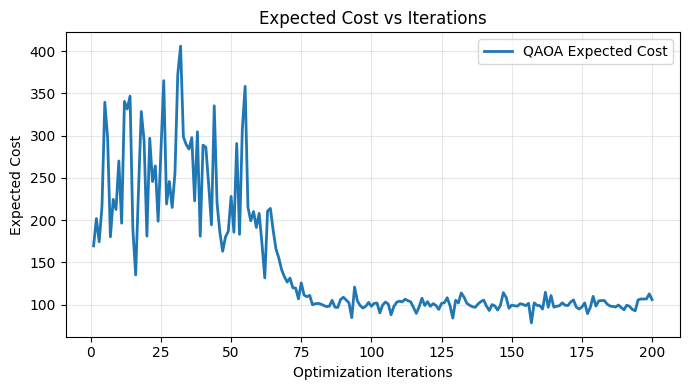

In [4]:
import pennylane as qml
from pennylane import numpy as np
import numpy as onp
import matplotlib.pyplot as plt

# 1. SYSTEM PARAMETERS
N = 3
BITS_PER_USER = 4
NUM_LEVELS = 16
NUM_QUBITS = N * BITS_PER_USER
P_MAX = onp.ones(N) * 0.3
P_TOTAL = 0.6
B = onp.ones(N) * 1e6
h = onp.array([1e-10, 1.5e-10, 0.7e-10])
N0_DBM_HZ = -174
P_LAYERS = 5
STEPS = 200
LEARNING_RATE = 0.05
PENALTY_LAMBDA = 20.0
P_REF = 0.02
SEED = 42

if len(P_MAX) != N or len(B) != N or len(h) != N:
    raise ValueError("System parameter arrays must have N entries.")
if P_TOTAL < 0:
    raise ValueError("Power budget must be nonnegative.")

# 2. NOISE POWER
noise_dbm = N0_DBM_HZ + 20 * onp.log10(B)
sigma_sq = 10 ** ((noise_dbm - 10) / 10)

# 3. BINARY ENCODING OF TRANSMIT POWER
NUM_STATES = 2 ** NUM_QUBITS

def decode_power(state):
    powers = onp.zeros(N)
    for n in range(N):
        shift = BITS_PER_USER * (N - 1 - n)
        level = (int(state) >> shift) & 15
        powers[n] = P_MAX[n] * level / 15
    return powers

# 4. TRANSMISSION RATE
def calculate_rates(powers):
    snr = powers * h / sigma_sq
    return B * onp.log2(1 + snr)

def calculate_sum_rate(powers):
    rates = calculate_rates(powers)
    return onp.sum(rates) / 1e6

# 5. PENALIZED COST FUNCTION
def calculate_cost(powers):
    total_rate = calculate_sum_rate(powers)
    total_power = onp.sum(powers)
    violation = max(0.0, (total_power - P_TOTAL) / P_REF)
    penalty = PENALTY_LAMBDA * violation ** 2
    return -total_rate + penalty

# 6. CONSTRUCT ALL BINARY CONFIGURATIONS
power_table = onp.array([decode_power(state) for state in range(NUM_STATES)])
rate_table = onp.array([calculate_sum_rate(powers) for powers in power_table])
cost_table = onp.array([calculate_cost(powers) for powers in power_table])

feasible = (onp.sum(power_table, axis=1) <= P_TOTAL + 1e-10)
feasible_states = onp.where(feasible)[0]

if len(feasible_states) == 0:
    raise RuntimeError("No feasible power allocations.")

# 7. QAOA COST HAMILTONIAN
energy_vector = np.array(cost_table, requires_grad=False)

# 8. INITIALIZE QUANTUM DEVICE
dev = qml.device("default.qubit", wires=NUM_QUBITS, shots=None)

# 9. QAOA QUANTUM CIRCUIT
@qml.qnode(dev, interface="autograd", diff_method="best")
def qaoa_circuit(params):
    for wire in range(NUM_QUBITS):
        qml.Hadamard(wires=wire)
    for layer in range(P_LAYERS):
        gamma = params[0, layer]
        beta = params[1, layer]
        phase_values = np.exp(-1j * gamma * energy_vector)
        qml.DiagonalQubitUnitary(phase_values, wires=range(NUM_QUBITS))
        for wire in range(NUM_QUBITS):
            qml.RX(2 * beta, wires=wire)
    return qml.probs(wires=range(NUM_QUBITS))

# 10. EXPECTED COST FUNCTION
def objective(params):
    probabilities = qaoa_circuit(params)
    return np.dot(probabilities, energy_vector)

# 11. INITIALIZE GAMMA AND BETA
rng = onp.random.default_rng(SEED)
initial_gamma = rng.uniform(0.0, 0.05, P_LAYERS)
initial_beta = rng.uniform(0.0, 0.5, P_LAYERS)
params = np.array([initial_gamma, initial_beta], requires_grad=True)

# 12. CLASSICAL PARAMETER OPTIMIZATION
optimizer = qml.AdamOptimizer(stepsize=LEARNING_RATE)
cost_history = []

for step in range(STEPS):
    params = optimizer.step(objective, params)
    current_cost = float(objective(params))
    cost_history.append(current_cost)
    print(f"Step {step+1:3d} | Cost = {current_cost:.6f}")

# 13. EXPECTED COST VS ITERATIONS (OBJECTIVE PLOT)
plt.figure(figsize=(7, 4))
plt.plot(range(1, STEPS + 1), cost_history, linewidth=2, label="QAOA Expected Cost")
plt.xlabel("Optimization Iterations")
plt.ylabel("Expected Cost")
plt.title("Expected Cost vs Iterations")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()